In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

<Axes: >

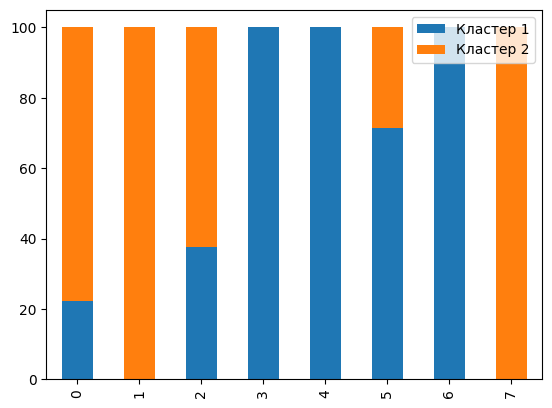

In [5]:
data = pd.DataFrame()
data['Карта'] = ['Storage 10','Storage 2','Storage 3','Storage 4','Storage 5','Storage 6','Storage 7','Storage 9']
data['Кластер 1'] = [22.2,0,37.5,100,100,71.4,100,0]
data['Кластер 2'] = data['Кластер 1'].apply(lambda x: 100-x)
data.plot(kind='bar',stacked=True)

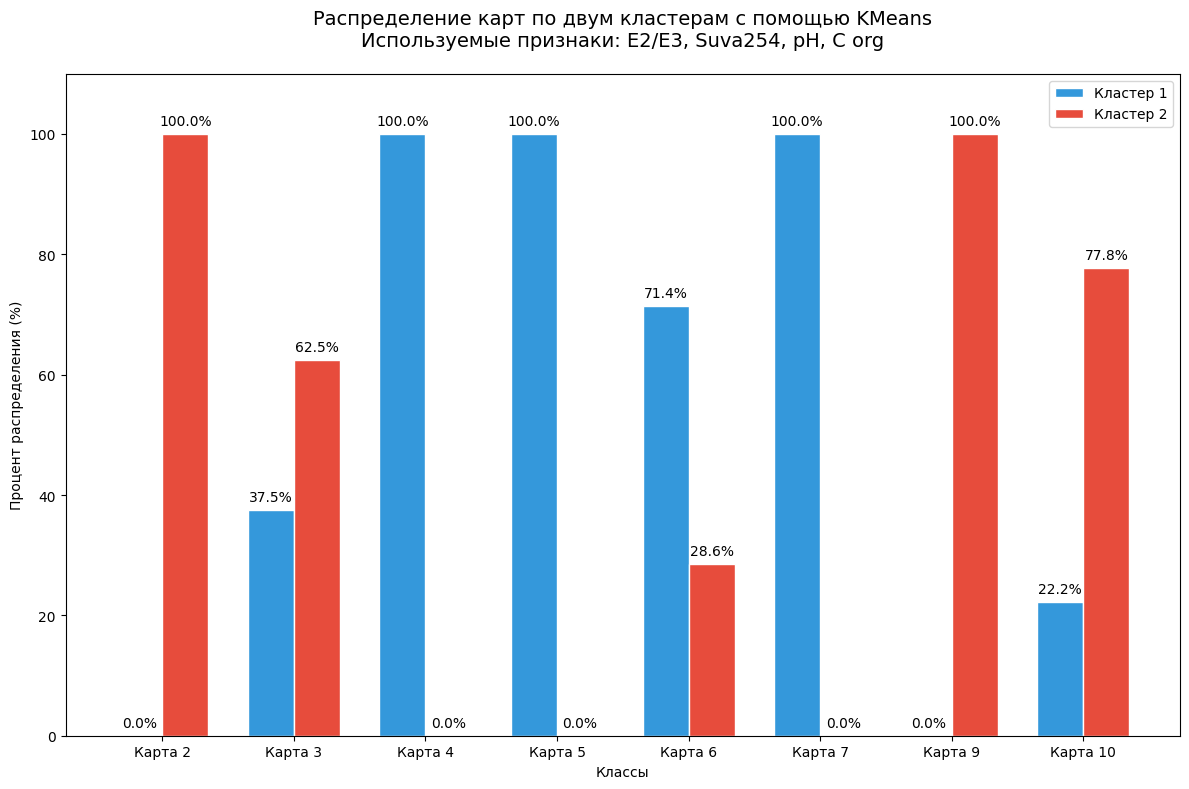

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Пример данных: для каждого класса распределение между двумя кластерами
data = {
    'Карта 2': [0, 100],  
    'Карта 3': [37.5, 62.5],
    'Карта 4': [100, 0],
    'Карта 5': [100, 0],
    'Карта 6': [71.4, 28.6],
    'Карта 7': [100, 0],
    'Карта 9': [0, 100],
    'Карта 10': [22.2, 77.8],
}

df = pd.DataFrame(data, index=['Кластер 1', 'Кластер 2'])

# Создание групповой столбчатой диаграммы
fig, ax = plt.subplots(figsize=(12, 8))

x = np.arange(len(df.columns))  # позиции классов
width = 0.35  # ширина столбцов

# Столбцы для двух кластеров
bars1 = ax.bar(x - width/2, df.loc['Кластер 1'], width, label='Кластер 1', 
               color='#3498db', edgecolor='white')
bars2 = ax.bar(x + width/2, df.loc['Кластер 2'], width, label='Кластер 2', 
               color='#e74c3c', edgecolor='white')

# Настройка оформления
ax.set_xlabel('Классы')
ax.set_ylabel('Процент распределения (%)')
ax.set_title('Распределение карт по двум кластерам с помощью KMeans\nИспользуемые признаки: E2/E3, Suva254, pH, C org', pad=20, size=14)
ax.set_xticks(x)
ax.set_xticklabels(df.columns)
ax.legend()
ax.set_ylim(0, 110)

# Добавление подписей значений
for bar in bars1:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 1,
            f'{height}%', ha='center', va='bottom')

for bar in bars2:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 1,
            f'{height}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()

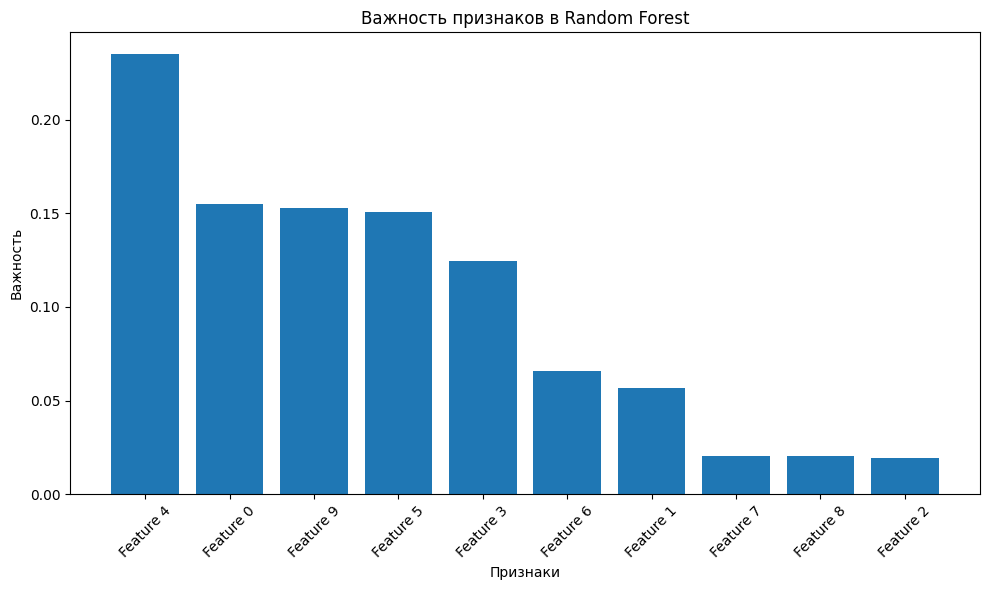

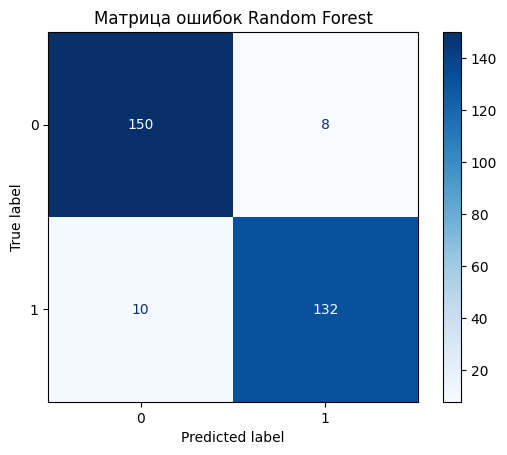

In [18]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification

# Создание или загрузка данных
X, y = make_classification(n_samples=1000, n_features=10, n_informative=5, 
                          n_redundant=2, random_state=42)

# Обучение модели
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X, y)

# Визуализация важности признаков
feature_importances = rf.feature_importances_
feature_names = [f'Feature {i}' for i in range(X.shape[1])]

# Сортировка по важности
indices = np.argsort(feature_importances)[::-1]

plt.figure(figsize=(10, 6))
plt.title("Важность признаков в Random Forest")
plt.bar(range(len(feature_importances)), feature_importances[indices])
plt.xticks(range(len(feature_importances)), [feature_names[i] for i in indices], rotation=45)
plt.xlabel("Признаки")
plt.ylabel("Важность")
plt.tight_layout()
plt.show()
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

# Разделение данных
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Обучение и предсказание
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

# Матрица ошибок
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.title("Матрица ошибок Random Forest")
plt.show()

In [20]:
feature_names

['Feature 0',
 'Feature 1',
 'Feature 2',
 'Feature 3',
 'Feature 4',
 'Feature 5',
 'Feature 6',
 'Feature 7',
 'Feature 8',
 'Feature 9']

c:\Users\mnbv2\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\ensemble\_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


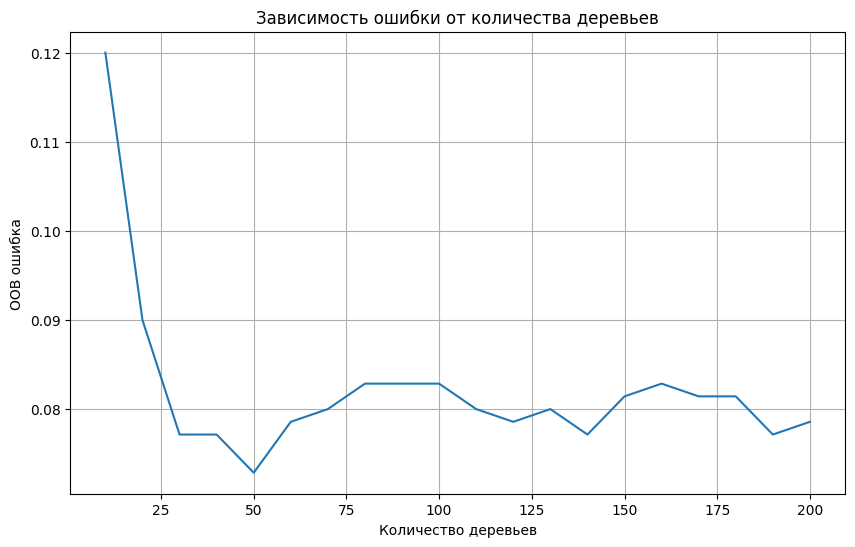

In [21]:
# С использованием Out-of-Bag ошибки
oob_errors = []
n_estimators_range = range(10, 201, 10)

for n_est in n_estimators_range:
    rf = RandomForestClassifier(n_estimators=n_est, 
                               oob_score=True, 
                               random_state=42)
    rf.fit(X_train, y_train)
    oob_errors.append(1 - rf.oob_score_)

plt.figure(figsize=(10, 6))
plt.plot(n_estimators_range, oob_errors)
plt.xlabel('Количество деревьев')
plt.ylabel('OOB ошибка')
plt.title('Зависимость ошибки от количества деревьев')
plt.grid(True)
plt.show()

Отчет о классификации:
              precision    recall  f1-score   support

           0       0.94      0.95      0.94       158
           1       0.94      0.93      0.94       142

    accuracy                           0.94       300
   macro avg       0.94      0.94      0.94       300
weighted avg       0.94      0.94      0.94       300



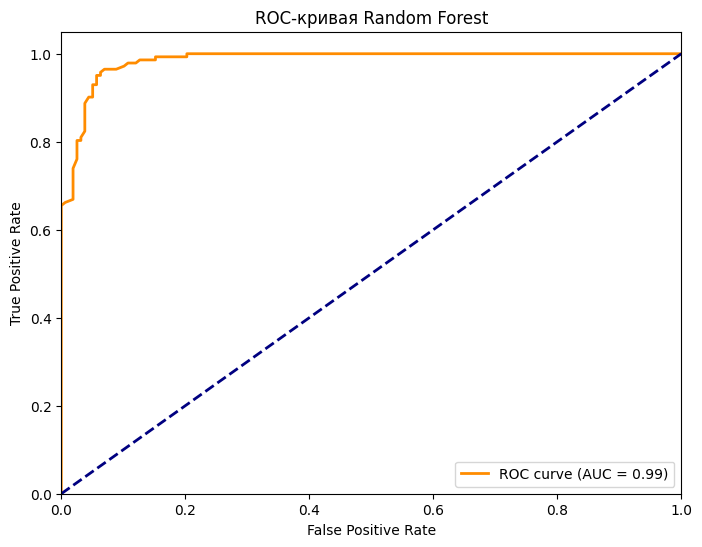

In [23]:
from sklearn.metrics import classification_report, precision_recall_curve, roc_curve, auc

# Текстовый отчет
print("Отчет о классификации:")
print(classification_report(y_test, y_pred))

# ROC-кривая
y_proba = rf.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривая Random Forest')
plt.legend(loc="lower right")
plt.show()

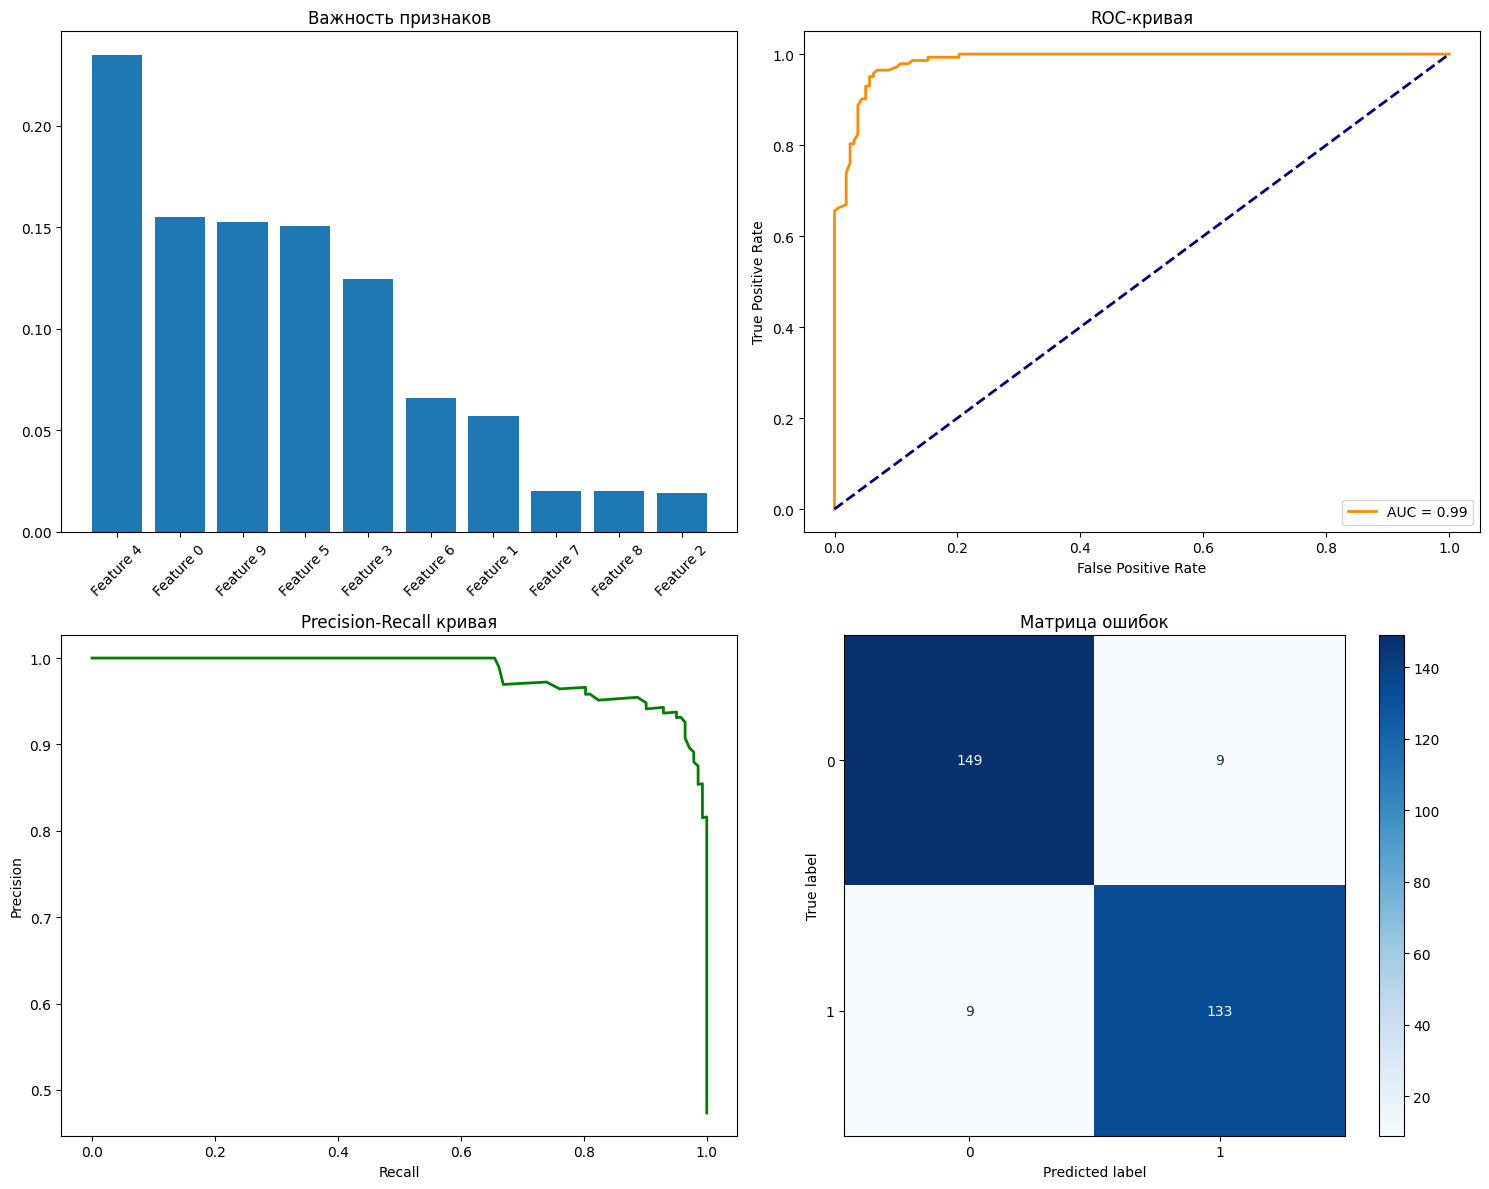

In [24]:
from sklearn.metrics import precision_recall_curve

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))

# 1. Важность признаков
ax1.bar(range(len(feature_importances)), feature_importances[indices])
ax1.set_title("Важность признаков")
ax1.set_xticks(range(len(feature_importances)))
ax1.set_xticklabels([feature_names[i] for i in indices], rotation=45)

# 2. ROC-кривая
ax2.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {roc_auc:.2f}')
ax2.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax2.set_title("ROC-кривая")
ax2.set_xlabel("False Positive Rate")
ax2.set_ylabel("True Positive Rate")
ax2.legend()

# 3. Precision-Recall кривая
precision, recall, _ = precision_recall_curve(y_test, y_proba)
ax3.plot(recall, precision, color='green', lw=2)
ax3.set_title("Precision-Recall кривая")
ax3.set_xlabel("Recall")
ax3.set_ylabel("Precision")

# 4. Матрица ошибок
ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test, ax=ax4, cmap='Blues')
ax4.set_title("Матрица ошибок")

plt.tight_layout()
plt.show()